<a href="https://colab.research.google.com/github/Marques07/IPCA-Prophet-vs-XGBoost/blob/main/02_Modelagem_Prophet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Prophet**


## **Level 1**

### This notebook is an extension of the main project file, which contains the full exploratory data analysis of the IPCA series. Here we focus exclusively on the Prophet model, both without and with exogenous variables. The data loading process is replicated below to keep this notebook self-contained and reproducible

In [21]:

import pandas as pd
import requests

codigos = {
    'ipca': 433,
    'selic': 4189,
    'cambio': 3698,
    'igpm': 189
}

dfs = {}
for nome, codigo in codigos.items():
    url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json'
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    df_temp = pd.DataFrame(response.json())
    df_temp['data'] = pd.to_datetime(df_temp['data'], format='%d/%m/%Y')
    df_temp['valor'] = pd.to_numeric(df_temp['valor'], errors='coerce')
    df_temp = df_temp.rename(columns={'valor': nome})
    dfs[nome] = df_temp

print("Series loaded:")
for nome, df in dfs.items():
    print(f"{nome}: {df.shape[0]} records | {df['data'].min().date()} até {df['data'].max().date()}")

Series loaded:
ipca: 558 records | 1980-01-01 até 2026-06-01
selic: 480 records | 1986-08-01 até 2026-07-01
cambio: 881 records | 1953-02-01 até 2026-06-01
igpm: 445 records | 1989-06-01 até 2026-06-01


We create a copy of the original IPCA DataFrame to avoid modifying the source
dictionary during subsequent transformations. This copy is stored in df_master,
and we then merge each of the remaining series (selic, cambio, igpm) using the
'data' column as the join key with an inner merge — keeping only dates present
across all series.

> Note: The exchange rate series (code 3694) was identified as annual frequency
and replaced by the monthly series (code 3698) prior to merging.

In [22]:
df_master = dfs['ipca'].copy()

for nome in ['selic', 'cambio', 'igpm']:
    df_master = df_master.merge(dfs[nome], on='data', how='inner')

We apply a temporal filter from January 2000 onwards. This cutoff was chosen
because the pre-2000 period includes extreme hyperinflation episodes that would
distort the model with patterns incompatible with the current monetary regime.
The year 2026 is reserved as the holdout set, given the limited number of
observations currently available for that period.

In [23]:
df_train = df_master[(df_master['data'] >= '2000-01-01') & (df_master['data'] <= '2025-12-01')].reset_index(drop=True)
df_test = df_master[(df_master['data'] >= '2026-01-01')].reset_index(drop=True)

print(f'Train: {df_train.shape} | From {df_train['data'].min().date()} to {df_train['data'].max().date()}')
print(f'Test: {df_test.shape} | From {df_test['data'].min().date()} to {df_test['data'].max().date()}')

Train: (312, 5) | From 2000-01-01 to 2025-12-01
Test: (6, 5) | From 2026-01-01 to 2026-06-01


Prophet requires two specific column names: 'ds' (datestamp) and 'y' (target variable).

In [24]:
from prophet import Prophet

df_proph = df_train[['data', 'ipca']].rename(columns={'data': 'ds', 'ipca': 'y'})

print(df_proph.shape)
print(df_proph.head())

(312, 2)
          ds     y
0 2000-01-01  0.62
1 2000-02-01  0.13
2 2000-03-01  0.22
3 2000-04-01  0.42
4 2000-05-01  0.01


We instantiate the model with additive seasonality, given the presence of deflation
in the historical series. Daily and weekly seasonalities are disabled since the data
is monthly.

In [25]:
model_proph = Prophet(
    seasonality_mode = 'additive',
    yearly_seasonality = True,
    weekly_seasonality = False,
    daily_seasonality = False,
    interval_width=0.80
)

model_proph.fit(df_proph)
print('Model fitted')

Model fitted


Since we want to forecast the future (2026), we need to create a DataFrame containing
those future dates for Prophet to fill with predictions.

In [26]:

periods_auto = len(df_test)
futuro = model_proph.make_future_dataframe(periods=periods_auto, freq = 'MS')
print(futuro.tail())

            ds
313 2026-02-01
314 2026-03-01
315 2026-04-01
316 2026-05-01
317 2026-06-01


With the trained model, we apply .predict() to compute the expected inflation values.
We extract yhat (our main estimate) along with yhat_lower and yhat_upper, which define
the uncertainty interval at the 80% confidence level set during model instantiation.

In [27]:
forecast = model_proph.predict(futuro)
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

            ds      yhat  yhat_lower  yhat_upper
313 2026-02-01  0.615791    0.177046    1.116091
314 2026-03-01  0.516568    0.035466    0.983150
315 2026-04-01  0.436859   -0.015228    0.905832
316 2026-05-01  0.291081   -0.190166    0.728521
317 2026-06-01  0.198402   -0.294590    0.668248


We generate a comparative chart between the actual values and the model's predictions.

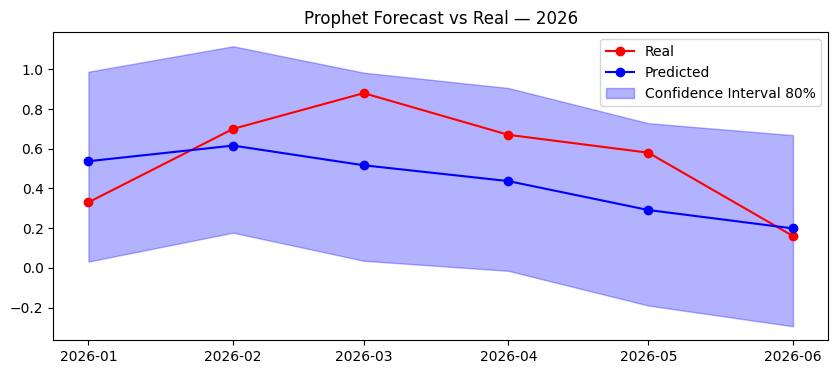

In [28]:
import matplotlib.pyplot as plt

forecast_2026 = forecast[forecast['ds'] >= '2026-01-01'][['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

plt.figure(figsize=(10, 4))
plt.plot(df_test['data'], df_test['ipca'], color='red', marker='o', label='Real')
plt.plot(forecast_2026['ds'], forecast_2026['yhat'], color='blue', marker='o', label='Predicted')
plt.fill_between(forecast_2026['ds'], forecast_2026['yhat_lower'], forecast_2026['yhat_upper'], alpha=0.3, color='blue', label='Confidence Interval 80%')
plt.title('Prophet Forecast vs Real — 2026')
plt.legend()
plt.show()

Since the IPCA series contains historically low values close to zero, including
deflationary months. Relative percentage metrics such as MAPE suffer severe
mathematical distortions. Therefore, MAE (Mean Absolute Error) is adopted as the
primary metric, measuring the real impact of errors in percentage points.

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_real = df_test['ipca'].values
y_pred = forecast[forecast['ds'] >= '2026-01-01']['yhat'].values

mae = mean_absolute_error(y_real, y_pred)
rmse = np.sqrt(mean_squared_error(y_real, y_pred))
#mape = np.mean(np.abs((y_real - y_pred) / y_real)) * 100 <- explicação abaixo

print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')

MAE: 0.2025
RMSE: 0.2314


**Trend:** The model identified a deceleration and continuous downward trend in IPCA
starting from the early 2000s, extending into early 2026. This descending force weighed on the
model, explaining why it failed to anticipate a short-term uptick.

**Yearly:** A strong and consistent seasonal pattern repeats every year, with a
notable spike between January and March. This behavior is perfectly aligned with
Brazilian economic reality — inflationary pressures at the start of the year driven
by service readjustments and education costs.

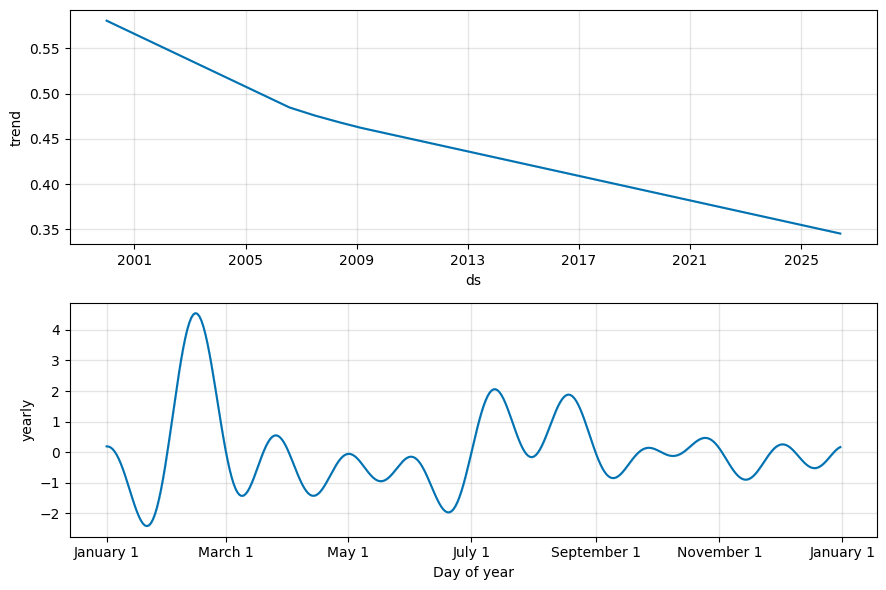

In [30]:
fig2 = model_proph.plot_components(forecast)
plt.show()

### **cross validation**



Standard cross-validation with random folds cannot be applied here, since we must
never use future data to predict the past. Instead, we use time-series cross-validation:
we take the first ~6.5 years as the initial training window and predict 3 months ahead;
then we advance the cutoff by 6 months and repeat until the end of the series.

With this approach: for short-term forecasts (roughly 30 days out), the expected
average error is ~0.30 p.p. For quarterly planning (90-day horizon), accuracy
improves and the historical error drops to ~0.17 p.p.

In [31]:
from prophet.diagnostics import cross_validation, performance_metrics

df_cv = cross_validation(
    model_proph,
    initial = '2400 days',
    period='180 days',
    horizon = '90 days'
)

df_metrics = performance_metrics(df_cv)
# Check the error at the end of the window (the worst-case/most realistic scenario for 3 months)
print("90-day horizon error:")
print(df_metrics.tail(1))

print('\n')
# Or view the entire table to understand the error curve
print(df_metrics[['horizon', 'mae', 'rmse']])


INFO:prophet:Making 39 forecasts with cutoffs between 2006-12-11 00:00:00 and 2025-09-02 00:00:00


  0%|          | 0/39 [00:00<?, ?it/s]

INFO:prophet:Skipping MAPE because y close to 0


90-day horizon error:
   horizon      mse      rmse       mae     mdape    smape  coverage
65 90 days  0.04754  0.218037  0.178238  0.369649  0.46877       1.0


   horizon       mae      rmse
0   9 days  0.302867  0.370146
1  10 days  0.325959  0.398640
2  11 days  0.330053  0.399666
3  13 days  0.291193  0.381159
4  14 days  0.294583  0.381858
..     ...       ...       ...
61 85 days  0.156075  0.195200
62 86 days  0.165602  0.201102
63 87 days  0.156739  0.197888
64 89 days  0.193232  0.234036
65 90 days  0.178238  0.218037

[66 rows x 3 columns]


## **LEVEL 2 - ADD REGRESSOR**

In Level 2, we incorporate exogenous variables into the model: SELIC interest rate,
USD/BRL exchange rate, and IGP-M. We maintain the same training cutoff and the same
additive configuration from Level 2. Note that the Prophet holidays feature is not
used here, since our variables are continuous time series rather than specific calendar
dates. The exogenous regressors are registered before fitting the model.

In [32]:
# Prepare the training dataset, including the regressors
df_train_reg = df_train[['data', 'ipca', 'selic', 'cambio', 'igpm']].copy()
df_train_reg = df_train_reg.rename(columns={'data': 'ds', 'ipca': 'y'})

# Initialize the new model (same base parameters as Level 2)
model_proph_reg = Prophet(
    seasonality_mode='additive',
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.80
)

# Add the exogenous variables
model_proph_reg.add_regressor('selic')
model_proph_reg.add_regressor('cambio')
model_proph_reg.add_regressor('igpm')

In [33]:
# Train the model
model_proph_reg.fit(df_train_reg)
print('Level 2 model trained with exogenous variables!')

Level 2 model trained with exogenous variables!


Unlike Level 1, Prophet now requires the future DataFrame to contain not only the
dates ('ds') but also the values of each registered regressor for the forecast
period. Since `df_master` already contains the full 2000–2026 data, we use it
directly, renaming the date column to 'ds'.

In [34]:

df_future_reg = df_master[['data', 'selic', 'cambio', 'igpm']].copy()
df_future_reg = df_future_reg.rename(columns={'data': 'ds'})

In [35]:
# forecasting
forecast_reg = model_proph_reg.predict(df_future_reg)
print(forecast_reg[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

            ds      yhat  yhat_lower  yhat_upper
440 2026-02-01  0.492755    0.107699    0.856925
441 2026-03-01  0.705499    0.364187    1.059327
442 2026-04-01  1.255526    0.892602    1.617045
443 2026-05-01  0.619886    0.255168    0.995118
444 2026-06-01  0.176332   -0.181580    0.508245


In [36]:
# Evaluating performance for the test period only (2026)
forecast_reg_2026 = forecast_reg[forecast_reg['ds'] >= '2026-01-01']

In [37]:
y_real_reg = df_test['ipca'].values
y_pred_reg = forecast_reg_2026['yhat'].values

mae_reg = mean_absolute_error(y_real_reg, y_pred_reg)
rmse_reg = np.sqrt(mean_squared_error(y_real_reg, y_pred_reg))

print('-' * 30)
print('LEVEL 2 RESULTS (With Exogenous Variables):')
print(f'MAE: {mae_reg:.4f}')
print(f'RMSE: {rmse_reg:.4f}')


------------------------------
LEVEL 2 RESULTS (With Exogenous Variables):
MAE: 0.2284
RMSE: 0.2996


### **Visual Comparison — Level 1 vs Level 2 vs Real**


The chart below overlays both Prophet models against the actual 2026 IPCA values,
making the performance gap between the pure and the regressor-based model visually
explicit.

The chart reveals that Prophet with exogenous variables tends to perform
particularly well during months where macroeconomic conditions shift
significantly, capturing movements that the pure model misses.


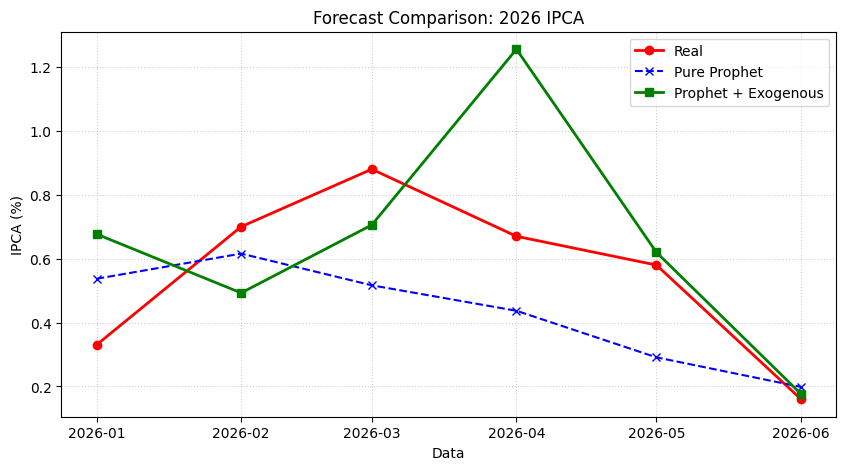

In [38]:
plt.figure(figsize=(10, 5))
# Real
plt.plot(df_test['data'], df_test['ipca'], color='red', marker='o', linewidth=2, label='Real')

# level 1
plt.plot(forecast_2026['ds'], forecast_2026['yhat'], color='blue', marker='x', linestyle='--', label='Pure Prophet')

# level 2
plt.plot(forecast_reg_2026['ds'], forecast_reg_2026['yhat'], color='green', marker='s', linewidth=2, label='Prophet + Exogenous')

plt.title('Forecast Comparison: 2026 IPCA')
plt.xlabel('Data')
plt.ylabel('IPCA (%)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Cross-Validation — Level 2

We repeat the same time-series cross-validation procedure applied in Level 1, using
the same initial window and horizon. This allows a direct comparison of how the
exogenous variables affect the model's generalization across the full historical
period.

With this approach: for short-term forecasts (roughly 30 days out), the expected average error is ~0.26 p.p. For quarterly planning (90-day horizon), accuracy improves and the historical error drops to ~0.18 p.p

In [39]:
from prophet.diagnostics import cross_validation, performance_metrics

df_cv_reg = cross_validation(
    model_proph_reg,
    initial = '2400 days',
    period='180 days',
    horizon = '90 days'
)

df_metrics_reg = performance_metrics(df_cv_reg)
# Consolidated error metrics for the maximum horizon (90 days)
print("Erro no horizonte de 90 dias:")
print(df_metrics_reg.tail(1))

print('\n')
# Full error progression across the forecast window
print(df_metrics_reg[['horizon', 'mae', 'rmse']])

INFO:prophet:Making 39 forecasts with cutoffs between 2006-12-11 00:00:00 and 2025-09-02 00:00:00


  0%|          | 0/39 [00:00<?, ?it/s]

INFO:prophet:Skipping MAPE because y close to 0


Erro no horizonte de 90 dias:
   horizon       mse      rmse       mae     mdape     smape  coverage
65 90 days  0.055085  0.234702  0.183065  0.356502  0.602698   0.69697


   horizon       mae      rmse
0   9 days  0.256526  0.379555
1  10 days  0.270355  0.382445
2  11 days  0.233793  0.362590
3  13 days  0.257922  0.366061
4  14 days  0.278262  0.376216
..     ...       ...       ...
61 85 days  0.178848  0.254585
62 86 days  0.154643  0.226763
63 87 days  0.179132  0.248119
64 89 days  0.179356  0.244114
65 90 days  0.183065  0.234702

[66 rows x 3 columns]


### **Results — Level 2 vs Level 1**




The comparison between both models reveals a nuanced picture. While aggregate
metrics across the full holdout period tend to favor the pure model, Level 2
demonstrates stronger sensitivity to macroeconomic shifts, capturing months
where conditions deviate significantly from historical seasonal patterns, as
visible in the chart above.

**Why does Level 2 sometimes underperform on average?**

Prophet's `add_regressor` assumes a linear and instantaneous relationship between
the regressor and the target. In practice, SELIC affects inflation with a lag of
6 to 12 months, not in the same month. By feeding the current value of SELIC to
explain the current IPCA, the model introduces noise rather than signal in most
months but captures real movements when those variables shift abruptly.

This confirms the need for an approach that handles lag structures explicitly,
which is exactly what we will address in the XGBoost models.

## **Live Forecast — Next Month**

This section generates a real forecast for the upcoming IPCA release, before the
official figure is published by IBGE. Both models are presented side by side
the pure Prophet as the most consistent baseline, and Prophet with regressors as
the most sensitive to current macroeconomic conditions.

> **Note:** Since the exogenous variables (SELIC, exchange rate, and IGP-M) for
> the forecast month are not yet available, the most recently recorded values are
> used as a proxy. This is a reasonable approximation for a one-month horizon,
> given that these variables tend not to shift abruptly between consecutive months.

Once the actual value is released, the predictions can be compared against the
result to validate both models in a real-world scenario.


In [40]:
# Next month not yet released
proximo_mes = df_master['data'].max() + pd.DateOffset(months=1)
periods_live = len(df_test) + 1

# ── Prophet level 1 ──────────────────────────────────────────────────────
futuro_live = model_proph.make_future_dataframe(periods=periods_live, freq='MS')
forecast_live = model_proph.predict(futuro_live)
prev_puro = forecast_live[forecast_live['ds'] == proximo_mes].iloc[0]

# ── Prophet + Regressors (level 2) ──────────────────────────────────────────────
# We need to ensure that df_future_reg also covers the next month.
# Since it is not yet in df_master, we manually create an extra row.
ultima_linha = df_master.iloc[-1]
linha_futura = pd.DataFrame([{
    'data': proximo_mes,
    'selic': ultima_linha['selic'],
    'cambio': ultima_linha['cambio'],
    'igpm': ultima_linha['igpm']
}])

df_future_live = pd.concat([
    df_master[['data', 'selic', 'cambio', 'igpm']],
    linha_futura
], ignore_index=True).rename(columns={'data': 'ds'})

forecast_live_reg = model_proph_reg.predict(df_future_live)
prev_reg = forecast_live_reg[forecast_live_reg['ds'] == proximo_mes].iloc[0]

# ── Result ─────────────────────────────────────────────────────────
print(f"--- Live Forecast: {proximo_mes.strftime('%B/%Y')} ---\n")
print(f"Prophet Pure         : {prev_puro['yhat']:.4f}%")
print(f"  Interval (80%)     : [{prev_puro['yhat_lower']:.4f}%, {prev_puro['yhat_upper']:.4f}%]")
print()
print(f"Prophet + Regressors : {prev_reg['yhat']:.4f}%")
print(f"  Interval (80%)     : [{prev_reg['yhat_lower']:.4f}%, {prev_reg['yhat_upper']:.4f}%]")

--- Live Forecast: July/2026 ---

Prophet Pure         : 0.2672%
  Interval (80%)     : [-0.2025%, 0.7186%]

Prophet + Regressors : 0.2299%
  Interval (80%)     : [-0.1518%, 0.5915%]
